# Lab 2 - Malware Detection (API CALLS)
Compare BoW, FFNN, RNN and GNN for malware classification from API call sequences.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


train_data = pd.read_json("train.json")
test_data = pd.read_json("test.json")

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

#train_data.head()
#test_data.head()

print("Label:", train_data.loc[0, "is_malware"])
print("First 10 API calls:", train_data.loc[0, "api_call_sequence"][:10])

Training samples: 16325
Test samples: 6505
Label: 1
First 10 API calls: ['LdrGetDllHandle', 'LdrGetProcedureAddress', 'LdrLoadDll', 'LdrGetProcedureAddress', 'LdrGetDllHandle', 'LdrGetProcedureAddress', 'GetTimeZoneInformation', 'LoadStringW', 'RegOpenKeyExW', 'RegQueryValueExW']


# Task1 - Analytics
Evaluating class distributions and other info

Training class counts:
is_malware
1    15714
0      611
Name: count, dtype: int64

Training class percentages:
is_malware
1    96.257274
0     3.742726
Name: proportion, dtype: float64

Test class counts:
is_malware
1    6262
0     243
Name: count, dtype: int64

Test class percentages:
is_malware
1    96.264412
0     3.735588
Name: proportion, dtype: float64
              Train         Test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000
              train         test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000


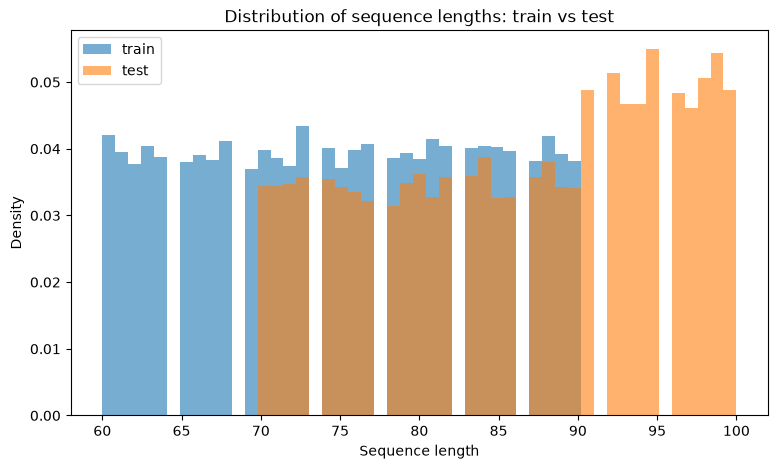

In [31]:

# Some info regarding the different class 
print("Training class counts:")
print(train_data["is_malware"].value_counts())

print("\nTraining class percentages:")# in percentuali 
print(train_data["is_malware"].value_counts(normalize=True).mul(100))

print("\nTest class counts:")
print(test_data["is_malware"].value_counts())

print("\nTest class percentages:")
print(test_data["is_malware"].value_counts(normalize=True).mul(100))

#max lenght of api_call_sequence

train_data["sequence_length"] = train_data["api_call_sequence"].apply(len)
test_data["sequence_length"] = test_data["api_call_sequence"].apply(len)

length_summary = pd.DataFrame({
    "Train": train_data["sequence_length"].describe(),
    "Test": test_data["sequence_length"].describe()
})

print(length_summary)

train_len = train_data["api_call_sequence"].apply(len)
test_len = test_data["api_call_sequence"].apply(len)

# Statistiche per confrontarli numericamente
print(pd.DataFrame({"train": train_len.describe(), "test": test_len.describe()}))

# Istogrammi con bin condivisi e density=True (train e test hanno dimensioni diverse)
bins = np.linspace(min(train_len.min(), test_len.min()),
                   max(train_len.max(), test_len.max()), 50)

plt.figure(figsize=(9, 5))
plt.hist(train_len, bins=bins, alpha=0.6, density=True, label="train")
plt.hist(test_len, bins=bins, alpha=0.6, density=True, label="test")
plt.xlabel("Sequence length")
plt.ylabel("Density")
plt.title("Distribution of sequence lengths: train vs test")
plt.legend()
plt.show()


## Train split & validation + Vocabulary


In [32]:
from sklearn.model_selection import train_test_split # type: ignore

train_split, val_split = train_test_split(
    train_data,
    test_size=0.2,
    stratify=train_data["is_malware"],
    random_state=42
)

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))

Training samples: 13060
Validation samples: 3265


In [33]:
# Vocabulary size

train_vocab = set()

for sequence in train_split["api_call_sequence"]:
    for call in sequence:
        train_vocab.add(call)

print("Vocabulary size:", len(train_vocab))

# Test one
test_vocab = set()

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        test_vocab.add(call)

unseen_calls = test_vocab - train_vocab

print("Distinct unseen test calls:", len(unseen_calls))
print("Unseen calls:", sorted(unseen_calls))

# Calcolo unseen calls per sample in the test set
samples_with_unseen = 0

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        if call not in train_vocab:
            samples_with_unseen += 1
            break

print("Test samples with unseen calls:", samples_with_unseen)

Vocabulary size: 256
Distinct unseen test calls: 3
Unseen calls: ['ControlService', 'NtDeleteKey', 'WSASocketA']
Test samples with unseen calls: 3


# Task2

### Simple First Vector visualization to understand

In [34]:
# To understand task 2A a visualization of all call number
# in train e val
from sklearn.feature_extraction.text import CountVectorizer 

# Le sequenze sono già liste di API: diciamo al vectorizer di usarle così come sono
def identity(seq):
    return seq

vectorizer = CountVectorizer(
    #analyzer="word",
    tokenizer=identity,
    token_pattern=None,
    lowercase=False, # Original value
    ngram_range=(1, 1)#solo singole chiamate
)

#obv la fit solo su train_split, poi trasformo sia train che val
X_train = vectorizer.fit_transform(train_split["api_call_sequence"])
X_val = vectorizer.transform(val_split["api_call_sequence"])

y_train = train_split["is_malware"]
y_val = val_split["is_malware"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

first_sample = pd.Series(
    X_train[0].toarray().ravel(),
    index=vectorizer.get_feature_names_out()
)

first_sample[first_sample > 0]

Training matrix: (13060, 256)
Validation matrix: (3265, 256)


CreateActCtxW                         1
GetNativeSystemInfo                   1
GetSystemDirectoryW                   2
GetSystemWindowsDirectoryW            4
GetVolumeNameForVolumeMountPointW     1
LdrGetProcedureAddress               11
LdrLoadDll                            5
LoadStringW                           1
NtClose                               5
NtCreateFile                          1
NtCreateMutant                        1
NtCreateSection                       1
NtDuplicateObject                     1
NtMapViewOfSection                    1
NtOpenKey                             2
NtQueryValueKey                       2
RegCloseKey                          14
RegEnumKeyW                           1
RegOpenKeyExA                         2
RegOpenKeyExW                        14
RegQueryValueExW                     10
dtype: int64

### Task 2A - Unigram Bag-of-Words
Represent each sequence using API call counts, ignoring call order, and train a baseline classifier.

#### Setup
Shared imports and settings for both BoW classifiers. (2A e 2B)

In [35]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


#### Unigram features
Fit API counts and scaling on training only. Apply the same transformations to validation.

In [36]:
vectorizer_uni = CountVectorizer(
    analyzer="word",
    tokenizer=identity,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 1),
)

X_train = vectorizer_uni.fit_transform(train_split[SEQ]).toarray()
X_val = vectorizer_uni.transform(val_split[SEQ]).toarray()

# Compress large counts without changing which APIs are present.
X_train = np.log1p(X_train)
X_val = np.log1p(X_val)

scaler_uni = StandardScaler()
X_train = scaler_uni.fit_transform(X_train)
X_val = scaler_uni.transform(X_val)

y_train = train_split[LABEL].to_numpy()
y_val = val_split[LABEL].to_numpy()

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
print("Unigram features:", X_train.shape[1])


Unigram features: 256


#### Shared BoW classifier
Two hidden layers (64 and 32 units), ReLU activations and one malware logit. Both representations use this architecture.

In [37]:
class BoWFFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


model_uni = BoWFFNN(X_train.shape[1])


#### Train the unigram model

In [38]:
loss_fn_uni = nn.BCEWithLogitsLoss()
optimizer_uni = torch.optim.Adam(model_uni.parameters(), lr=LEARNING_RATE)
loader_uni = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

for epoch in range(EPOCHS):
    model_uni.train()
    total_loss = 0
    for xb, yb in loader_uni:
        optimizer_uni.zero_grad()
        loss = loss_fn_uni(model_uni(xb), yb)
        loss.backward()
        optimizer_uni.step()
        total_loss += loss.item()
    print(f"Epoch {epoch + 1}/{EPOCHS} - mean loss: {total_loss / len(loader_uni):.4f}")


Epoch 1/20 - mean loss: 0.2013
Epoch 2/20 - mean loss: 0.0822
Epoch 3/20 - mean loss: 0.0639
Epoch 4/20 - mean loss: 0.0521
Epoch 5/20 - mean loss: 0.0441
Epoch 6/20 - mean loss: 0.0388
Epoch 7/20 - mean loss: 0.0349
Epoch 8/20 - mean loss: 0.0322
Epoch 9/20 - mean loss: 0.0293
Epoch 10/20 - mean loss: 0.0270
Epoch 11/20 - mean loss: 0.0250
Epoch 12/20 - mean loss: 0.0248
Epoch 13/20 - mean loss: 0.0240
Epoch 14/20 - mean loss: 0.0245
Epoch 15/20 - mean loss: 0.0225
Epoch 16/20 - mean loss: 0.0192
Epoch 17/20 - mean loss: 0.0189
Epoch 18/20 - mean loss: 0.0207
Epoch 19/20 - mean loss: 0.0185
Epoch 20/20 - mean loss: 0.0182


#### Evaluate on validation

              precision    recall  f1-score   support

           0     0.7733    0.4754    0.5888       122
           1     0.9799    0.9946    0.9872      3143

    accuracy                         0.9752      3265
   macro avg     0.8766    0.7350    0.7880      3265
weighted avg     0.9722    0.9752    0.9723      3265



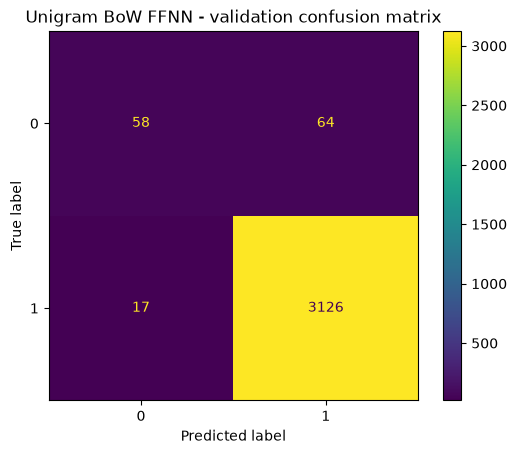

In [39]:
model_uni.eval()
with torch.no_grad():
    probs_val_uni = torch.sigmoid(model_uni(X_val_t))
    y_pred_val_uni = (probs_val_uni > 0.5).int().numpy()

report_uni = classification_report(y_val, y_pred_val_uni, digits=4)
cm_uni = confusion_matrix(y_val, y_pred_val_uni)
print(report_uni)
ConfusionMatrixDisplay(cm_uni).plot()
plt.title("Unigram BoW FFNN - validation confusion matrix")
plt.show()


### Task 2B - Unigrams + bigrams
Add adjacent API pairs while keeping preprocessing, architecture and training settings the same.

#### Unigram and bigram features

In [40]:
# Repeat the steps for clarity, using the SAME train_split and val_split.
# Reuse X/y names: X_train and X_val now contain unigrams + bigrams.
# Keep fitted models, vectorizers and scalers separate.

vectorizer_bi = CountVectorizer(
    analyzer="word",
    tokenizer=identity,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
)

X_train = vectorizer_bi.fit_transform(train_split[SEQ]).toarray()
X_val = vectorizer_bi.transform(val_split[SEQ]).toarray()

X_train = np.log1p(X_train)
X_val = np.log1p(X_val)

scaler_bi = StandardScaler()
X_train = scaler_bi.fit_transform(X_train)
X_val = scaler_bi.transform(X_val)

y_train = train_split[LABEL].to_numpy()
y_val = val_split[LABEL].to_numpy()

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
print("Unigram + bigram features:", X_train.shape[1])


Unigram + bigram features: 5741


#### Create the bigram model
Reuse the shared class, adjusting only the input size.

In [41]:
model_bi = BoWFFNN(X_train.shape[1])


#### Train the bigram model

In [42]:
loss_fn_bi = nn.BCEWithLogitsLoss()
optimizer_bi = torch.optim.Adam(model_bi.parameters(), lr=LEARNING_RATE)
loader_bi = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

for epoch in range(EPOCHS):
    model_bi.train()
    total_loss = 0
    for xb, yb in loader_bi:
        optimizer_bi.zero_grad()
        loss = loss_fn_bi(model_bi(xb), yb)
        loss.backward()
        optimizer_bi.step()
        total_loss += loss.item()
    print(f"Epoch {epoch + 1}/{EPOCHS} - mean loss: {total_loss / len(loader_bi):.4f}")


Epoch 1/20 - mean loss: 0.1347
Epoch 2/20 - mean loss: 0.0413
Epoch 3/20 - mean loss: 0.0229
Epoch 4/20 - mean loss: 0.0174
Epoch 5/20 - mean loss: 0.0143
Epoch 6/20 - mean loss: 0.0121
Epoch 7/20 - mean loss: 0.0115
Epoch 8/20 - mean loss: 0.0109
Epoch 9/20 - mean loss: 0.0102
Epoch 10/20 - mean loss: 0.0092
Epoch 11/20 - mean loss: 0.0091
Epoch 12/20 - mean loss: 0.0093
Epoch 13/20 - mean loss: 0.0092
Epoch 14/20 - mean loss: 0.0084
Epoch 15/20 - mean loss: 0.0078
Epoch 16/20 - mean loss: 0.0081
Epoch 17/20 - mean loss: 0.0072
Epoch 18/20 - mean loss: 0.0083
Epoch 19/20 - mean loss: 0.0076
Epoch 20/20 - mean loss: 0.0081


#### Evaluate on validation

              precision    recall  f1-score   support

           0     0.7838    0.7131    0.7468       122
           1     0.9889    0.9924    0.9906      3143

    accuracy                         0.9819      3265
   macro avg     0.8863    0.8527    0.8687      3265
weighted avg     0.9812    0.9819    0.9815      3265



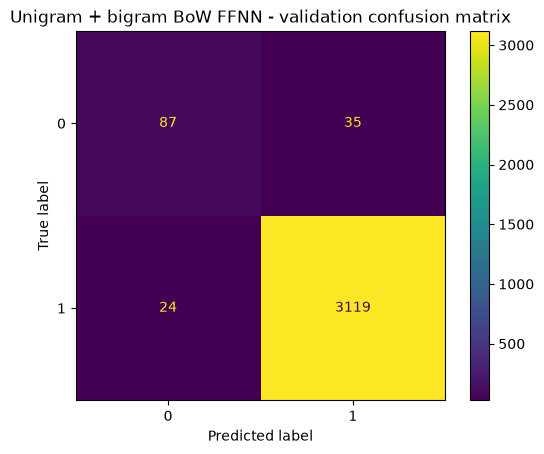

In [43]:
model_bi.eval()
with torch.no_grad():
    probs_val_bi = torch.sigmoid(model_bi(X_val_t))
    y_pred_val_bi = (probs_val_bi > 0.5).int().numpy()

report_bi = classification_report(y_val, y_pred_val_bi, digits=4)
cm_bi = confusion_matrix(y_val, y_pred_val_bi)
print(report_bi)
ConfusionMatrixDisplay(cm_bi).plot()
plt.title("Unigram + bigram BoW FFNN - validation confusion matrix")
plt.show()


# Task 3

Task 3A

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)

# =========================================================
# 1. DA API A ID INTERI (comune a entrambi gli encoding)
# =========================================================

PAD, UNK = 0, 1   # 0 = padding, 1 = API mai vista nel train

# Vocabolario costruito SOLO sul train: ogni API riceve un ID da 2 in su
api_list = sorted({api for seq in train_pd[SEQ] for api in seq})
vocab = {api: i + 2 for i, api in enumerate(api_list)}
VOCAB_SIZE = len(vocab) + 2   # +2 per PAD e UNK

# Lunghezza fissa = sequenza più lunga del train
MAX_LEN = train_pd[SEQ].apply(len).max()
print("API distinte:", len(vocab), "- MAX_LEN:", MAX_LEN)

def encode(seq):
    ids = [vocab.get(api, UNK) for api in seq[:MAX_LEN]]   # tronca tenendo l'inizio
    return ids + [PAD] * (MAX_LEN - len(ids))               # padding fino a MAX_LEN

ids_train = np.array([encode(s) for s in train_pd[SEQ]])   # forma: (n_sequenze, MAX_LEN)
ids_test  = np.array([encode(s) for s in test_pd[SEQ]])

y_train = torch.tensor(train_pd[LABEL].values, dtype=torch.float32)
y_test  = test_pd[LABEL].values

# =========================================================
# 2. ARCHITETTURA 
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),   # strato nascosto 1
            nn.Linear(64, 32),     nn.ReLU(),   # strato nascosto 2
            nn.Linear(32, 1),                   # output: 1 logit
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

# =========================================================
# 3. TRAINING E VALUTAZIONE 
# =========================================================

def train_and_evaluate(model, X_train, X_test, name, epochs=20):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{name}] Epoca {epoch + 1}/{epochs} - loss: {total_loss / len(loader):.4f}")

    model.eval()
    with torch.no_grad():
        y_pred = (torch.sigmoid(model(X_test)) > 0.5).int().numpy()

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
    plt.title(f"{name} - confusion matrix sul test")
    plt.show()
    return y_pred

# =========================================================
# 4. ENCODING (a): ID INTERI + StandardScaler
# =========================================================

# Ogni posizione della sequenza è una feature: la standardizziamo
scaler = StandardScaler()
Xa_train = torch.tensor(scaler.fit_transform(ids_train), dtype=torch.float32)
Xa_test  = torch.tensor(scaler.transform(ids_test),      dtype=torch.float32)

model_a = FFNN(in_dim=MAX_LEN)   # input: MAX_LEN numeri
y_pred_ids = train_and_evaluate(model_a, Xa_train, Xa_test, "Integer IDs")

NameError: name 'train_pd' is not defined

Task 3B

API distinte: 258 - MAX_LEN: 90
[Embeddings] Epoca 1/20 - loss: 0.1636
[Embeddings] Epoca 2/20 - loss: 0.1155
[Embeddings] Epoca 3/20 - loss: 0.0849
[Embeddings] Epoca 4/20 - loss: 0.0530
[Embeddings] Epoca 5/20 - loss: 0.0323
[Embeddings] Epoca 6/20 - loss: 0.0208
[Embeddings] Epoca 7/20 - loss: 0.0139
[Embeddings] Epoca 8/20 - loss: 0.0129
[Embeddings] Epoca 9/20 - loss: 0.0116
[Embeddings] Epoca 10/20 - loss: 0.0075
[Embeddings] Epoca 11/20 - loss: 0.0080
[Embeddings] Epoca 12/20 - loss: 0.0084
[Embeddings] Epoca 13/20 - loss: 0.0090
[Embeddings] Epoca 14/20 - loss: 0.0071
[Embeddings] Epoca 15/20 - loss: 0.0063
[Embeddings] Epoca 16/20 - loss: 0.0069
[Embeddings] Epoca 17/20 - loss: 0.0052
[Embeddings] Epoca 18/20 - loss: 0.0041
[Embeddings] Epoca 19/20 - loss: 0.0048
[Embeddings] Epoca 20/20 - loss: 0.0053

===== Embeddings =====
              precision    recall  f1-score   support

           0     0.2330    0.1687    0.1957       243
           1     0.9681    0.9784    0.9732 

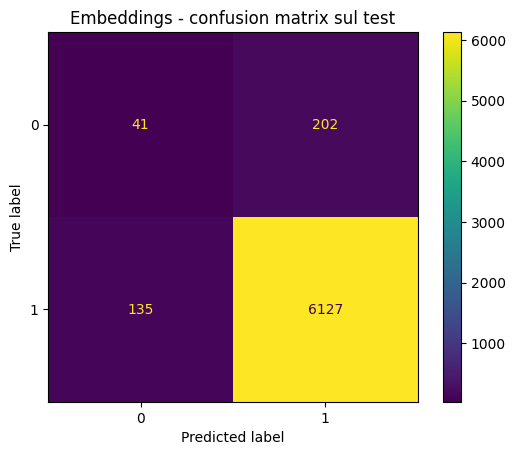

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEQ, LABEL = "api_call_sequence", "is_malware"
torch.manual_seed(42)

# =========================================================
# 1. DA API A ID INTERI 
# =========================================================

PAD, UNK = 0, 1   # 0 = padding, 1 = API mai vista nel train

# Vocabolario costruito SOLO sul train: ogni API riceve un ID da 2 in su
api_list = sorted({api for seq in train_pd[SEQ] for api in seq})
vocab = {api: i + 2 for i, api in enumerate(api_list)}
VOCAB_SIZE = len(vocab) + 2   # +2 per PAD e UNK

# Lunghezza fissa = sequenza più lunga del train
MAX_LEN = train_pd[SEQ].apply(len).max()
print("API distinte:", len(vocab), "- MAX_LEN:", MAX_LEN)

def encode(seq):
    ids = [vocab.get(api, UNK) for api in seq[:MAX_LEN]]   # tronca tenendo l'inizio
    return ids + [PAD] * (MAX_LEN - len(ids))               # padding fino a MAX_LEN

ids_train = np.array([encode(s) for s in train_pd[SEQ]])   # forma: (n_sequenze, MAX_LEN)
ids_test  = np.array([encode(s) for s in test_pd[SEQ]])

y_train = torch.tensor(train_pd[LABEL].values, dtype=torch.float32)
y_test  = test_pd[LABEL].values

# =========================================================
# 2. ARCHITETTURA COMUNE 
# =========================================================

class FFNN(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),   # strato nascosto 1
            nn.Linear(64, 32),     nn.ReLU(),   # strato nascosto 2
            nn.Linear(32, 1),                   # output: 1 logit
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

# =========================================================
# 3. TRAINING E VALUTAZIONE 
# =========================================================

def train_and_evaluate(model, X_train, X_test, name, epochs=20):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"[{name}] Epoca {epoch + 1}/{epochs} - loss: {total_loss / len(loader):.4f}")

    model.eval()
    with torch.no_grad():
        y_pred = (torch.sigmoid(model(X_test)) > 0.5).int().numpy()

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
    plt.title(f"{name} - confusion matrix sul test")
    plt.show()
    return y_pred

# =========================================================
# 4. ENCODING (b): EMBEDDING ADDESTRABILI
# =========================================================

EMB_DIM = 16

class EmbeddingFFNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Tabella addestrabile: ogni ID -> vettore di 16 numeri (il PAD resta a zero)
        self.emb = nn.Embedding(VOCAB_SIZE, EMB_DIM, padding_idx=PAD)
        # Stessa architettura di (a): cambia solo la dimensione dell'input
        self.ffnn = FFNN(in_dim=MAX_LEN * EMB_DIM)

    def forward(self, x):
        x = self.emb(x)         # (batch, MAX_LEN) -> (batch, MAX_LEN, 16)
        x = x.flatten(1)        # -> (batch, MAX_LEN * 16): un unico vettore
        return self.ffnn(x)

# L'embedding vuole ID interi (long), NON scalati
Xb_train = torch.tensor(ids_train, dtype=torch.long)
Xb_test  = torch.tensor(ids_test,  dtype=torch.long)

model_b = EmbeddingFFNN()
y_pred_emb = train_and_evaluate(model_b, Xb_train, Xb_test, "Embeddings")

#Entrambi i modelli raggiungono un’accuracy di circa il 95%, valore vicino a quello di un classificatore che predice sempre la classe maggioritaria e quindi poco informativo a causa del forte sbilanciamento. La macro F1 mostra invece prestazioni limitate: 0.52 per gli ID interi e 0.58 per gli embedding. Gli embedding migliorano soprattutto la recall sulla classe minoritaria, perché imparano una rappresentazione delle API in cui chiamate simili hanno vettori simili, mentre gli ID interi impongono un ordinamento arbitrario. In entrambi i casi l’assenza di una gestione dello sbilanciamento porta il modello a favorire la classe maggioritaria.